# Deepfake Temporal ViT - Master Training Notebook

This notebook contains all the robust PyTorch fixes, Google Drive integration, and the Celeb-DF v2 public dataset setup. It is optimized for the Free Colab T4 GPU.

In [ ]:
# 1. Mount Google Drive to save our models and graphs securely
from google.colab import drive
drive.mount('/content/drive')

import os
drive_output_dir = '/content/drive/MyDrive/Deepfake_ViT_Outputs'
os.makedirs(drive_output_dir, exist_ok=True)
os.makedirs(os.path.join(drive_output_dir, 'figures'), exist_ok=True)
print(f"All outputs will be saved permanently to: {drive_output_dir}")

Mounted at /content/drive
All outputs will be saved permanently to: /content/drive/MyDrive/Deepfake_ViT_Outputs


In [ ]:
# 2. Install dependencies & Extract the project zip
!pip install facenet-pytorch kaggle --quiet --no-deps

import os
if os.path.exists('Deepfake_Temporal_ViT_Submission.zip'):
    !unzip -q -o Deepfake_Temporal_ViT_Submission.zip
    print("Project files extracted successfully!")
else:
    print("\n!!! UPLOAD Deepfake_Temporal_ViT_Submission.zip to the files panel on the left BEFORE RUNNING !!!")

import sys
sys.path.append('/content')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 23.3 MB/s eta 0:00:00
Project files extracted successfully!


In [ ]:
# 3. Authenticate Kaggle & Download Celeb-DF v2 Dataset (~9GB)
import os

# !!! REPLACE 'YOUR_KAGGLE_USERNAME' WITH YOUR ACTUAL KAGGLE USERNAME !!!
os.environ['KAGGLE_USERNAME'] = "YOUR_KAGGLE_USERNAME"
os.environ['KAGGLE_KEY'] = "KGAT_744f7a38a13bb2430c86ba096a10362a"

print("Downloading Celeb-DF v2 dataset (~9GB). This may take a few minutes...")
!kaggle datasets download -d reubensuju/celeb-df-v2
!mkdir -p /content/real_data
!unzip -q -o celeb-df-v2.zip -d /content/real_data
print("Dataset extracted successfully!")

Dataset URL: https://www.kaggle.com/datasets/reubensuju/celeb-df-v2
License(s): unknown
100% 9.29G/9.29G [01:41<00:00, 98.6MB/s]

Dataset extracted successfully!


In [ ]:
# 4. Setup Dataloaders from Real Data
import glob
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
from src.dataset import DeepfakeVideoDataset

print("Setting up paths and labels...")
real_videos = glob.glob('/content/real_data/Celeb-real/*.mp4')[:500]
fake_videos = glob.glob('/content/real_data/Celeb-synthesis/*.mp4')[:500]

video_paths = real_videos + fake_videos
labels = [0]*len(real_videos) + [1]*len(fake_videos)
print(f"Loaded {len(real_videos)} real and {len(fake_videos)} fake videos for training!")

train_paths, val_paths, train_labels, val_labels = train_test_split(
    video_paths, labels, test_size=0.2, random_state=42
)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

# Device passed to dataset to use GPU for MTCNN, num_workers=0 to prevent OpenCV deadlocks
train_dataset = DeepfakeVideoDataset(train_paths, train_labels, sequence_length=8, augment=True, device=device)
val_dataset = DeepfakeVideoDataset(val_paths, val_labels, sequence_length=8, augment=False, device=device)

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=0)

Setting up paths and labels...
Loaded 500 real and 500 fake videos for training!
Using device: cuda


In [ ]:
# 5. Initialize Model, Loss, Optimizer, and Scheduler
import torch.nn as nn
import torch.optim as optim
from src.models.temporal_vit import AdvancedTemporalViT

model = AdvancedTemporalViT(use_mocks=False).to(device)
model.classifier[-1] = nn.Identity()  # Strip Sigmoid for BCEWithLogitsLoss

# Unfreeze the last layer of the ViT backbone so it learns deepfake features!
for param in model.vit.layers[-1].parameters():
    param.requires_grad = True

criterion = nn.BCEWithLogitsLoss()
# Reduced Learning Rate to 1e-4
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
scaler = torch.amp.GradScaler('cuda')

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

In [ ]:
# 6. Training Loop (with Google Drive saving and Gradient Accumulation)
EPOCHS = 20
best_val_loss = float('inf')
accumulation_steps = 4  # Simulates batch size of 16 to stabilize gradients
drive_model_path = '/content/drive/MyDrive/Deepfake_ViT_Outputs/best_model.pth'

print("Starting Real-World Training with Gradient Accumulation...")
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    optimizer.zero_grad()

    for i, (x, res, label) in enumerate(train_loader):
        x, res, label = x.to(device), res.to(device), label.to(device)

        with torch.amp.autocast('cuda'):
            logits = model(x, res).squeeze(-1)
            loss = criterion(logits, label.float())
            loss = loss / accumulation_steps

        scaler.scale(loss).backward()

        if (i + 1) % accumulation_steps == 0 or (i + 1) == len(train_loader):
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        train_loss += (loss.item() * accumulation_steps) * x.size(0)

    train_loss /= len(train_loader.dataset)

    # Validation Loop
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x, res, label in val_loader:
            x, res, label = x.to(device), res.to(device), label.to(device)
            with torch.amp.autocast('cuda'):
                logits = model(x, res).squeeze(-1)
                loss = criterion(logits, label.float())
            val_loss += loss.item() * x.size(0)

    val_loss /= len(val_loader.dataset)
    scheduler.step(val_loss)

    print(f"Epoch {epoch+1}/{EPOCHS} - Train Loss: {train_loss:.4f} - Val Loss: {val_loss:.4f}")
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        # Save directly to Google Drive!
        torch.save(model.state_dict(), drive_model_path)
        print(f"Saved new best model securely to Google Drive!")

Starting Real-World Training with Gradient Accumulation...
Epoch 1/20 - Train Loss: 0.6947 - Val Loss: 0.6948
Saved new best model securely to Google Drive!
Epoch 2/20 - Train Loss: 0.6879 - Val Loss: 0.6517
Saved new best model securely to Google Drive!
Epoch 3/20 - Train Loss: 0.6349 - Val Loss: 0.6633
Epoch 4/20 - Train Loss: 0.5040 - Val Loss: 0.5943
Saved new best model securely to Google Drive!
Epoch 5/20 - Train Loss: 0.3789 - Val Loss: 0.5344
Saved new best model securely to Google Drive!
Epoch 6/20 - Train Loss: 0.2966 - Val Loss: 0.5772
Epoch 7/20 - Train Loss: 0.3257 - Val Loss: 0.5866
Epoch 8/20 - Train Loss: 0.3140 - Val Loss: 0.6633
Epoch 9/20 - Train Loss: 0.1963 - Val Loss: 0.5246
Saved new best model securely to Google Drive!
Epoch 10/20 - Train Loss: 0.1223 - Val Loss: 0.5639
Epoch 11/20 - Train Loss: 0.1098 - Val Loss: 0.5901
Epoch 12/20 - Train Loss: 0.0729 - Val Loss: 0.6182
Epoch 13/20 - Train Loss: 0.0573 - Val Loss: 0.6366
Epoch 14/20 - Train Loss: 0.0515 - Val 

KeyboardInterrupt: 

Generating Final Evaluation Metrics...


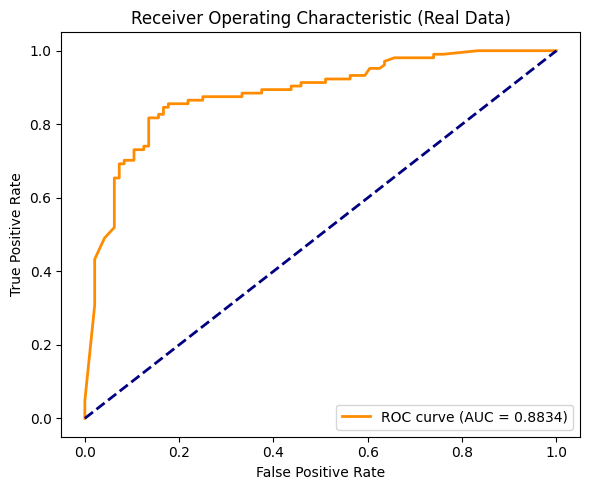

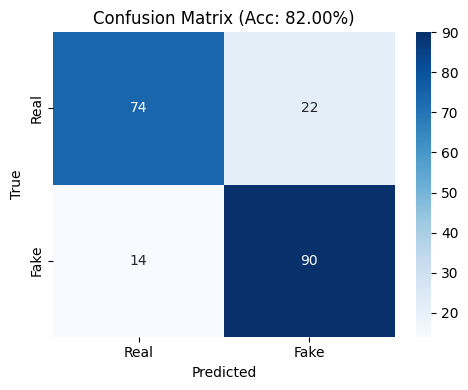

Final Validation Accuracy: 0.8200
Final AUC: 0.8834

All graphs and the best model weights have been saved to: /content/drive/MyDrive/Deepfake_ViT_Outputs


In [ ]:
# 7. Final Evaluation & Saving Graphs to Drive
from sklearn.metrics import roc_curve, auc, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

print("Generating Final Evaluation Metrics...")
model.load_state_dict(torch.load(drive_model_path))
model.eval()

y_true, y_scores = [], []
with torch.no_grad():
    for x, res, label in val_loader:
        x, res = x.to(device), res.to(device)
        with torch.amp.autocast('cuda'):
            logits = model(x, res).squeeze(-1)
            probs = torch.sigmoid(logits)
        y_true.extend(label.numpy())
        y_scores.extend(probs.cpu().numpy())

y_pred = [1 if p >= 0.5 else 0 for p in y_scores]

# ROC Curve
fpr, tpr, _ = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (Real Data)')
plt.legend(loc="lower right")
plt.tight_layout()
roc_path = '/content/drive/MyDrive/Deepfake_ViT_Outputs/figures/roc_curve.png'
plt.savefig(roc_path)
plt.show()

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
plt.title(f'Confusion Matrix (Acc: {accuracy_score(y_true, y_pred):.2%})')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.tight_layout()
cm_path = '/content/drive/MyDrive/Deepfake_ViT_Outputs/figures/confusion_matrix.png'
plt.savefig(cm_path)
plt.show()

print(f"Final Validation Accuracy: {accuracy_score(y_true, y_pred):.4f}")
print(f"Final AUC: {roc_auc:.4f}")
print(f"\nAll graphs and the best model weights have been saved to: {drive_output_dir}")